# ETH Daily Options Analysis

Daily options are the **highest theta, highest gamma** contracts on the chain.

Every day at **1:30 PM IST** (08:00 UTC), the shortest expiry settles.

**This notebook analyzes:**

1. What daily expiries exist right now
2. Strike distribution for the nearest expiry
3. IV skew at the shortest tenor
4. Gamma concentration (buyer's leverage)
5. Theta burn (cost per hour)
6. Liquidity by strike
7. Best daily contract for a buyer
8. The daily option buyer's verdict

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from datetime import datetime, timezone, timedelta
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)

DERIBIT = 'https://www.deribit.com/api/v2/public'
CURRENCY = 'ETH'

# IST = UTC + 5:30
IST_OFFSET = timedelta(hours=5, minutes=30)

def to_ist(dt):
    if dt.tzinfo is None:
        dt = dt.replace(tzinfo=timezone.utc)
    return dt.astimezone(timezone(IST_OFFSET))

print('ready')

ready


## 1. Fetch full ETH chain and filter to daily expiries

**Daily options** = expiries within the next 1-3 days. These are the contracts that expire every day at 1:30 PM IST.

In [2]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=20)
    r.raise_for_status()
    return r.json()['result']


def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4:
        return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(
            tzinfo=timezone.utc, hour=8, minute=0)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None


raw = fetch_chain(CURRENCY)
now_ms = int(time.time() * 1000)

rows = []
for r in raw:
    p = parse_name(r['instrument_name'])
    if p is None: continue
    rows.append({
        'instrument': r['instrument_name'],
        'expiry': p[0],
        'strike': p[1],
        'kind': p[2],
        'days': (p[0] - now_ms) / 86_400_000,
        'mark': r.get('mark_price'),
        'bid': r.get('bid_price'),
        'ask': r.get('ask_price'),
        'iv': r.get('mark_iv'),
        'oi': r.get('open_interest') or 0,
        'volume': r.get('volume') or 0,
        'underlying': r.get('underlying_price'),
    })

df_all = pd.DataFrame(rows)
df_all['expiry_dt'] = pd.to_datetime(df_all.expiry, unit='ms', utc=True).dt.tz_convert(None)
df_all['iv_dec'] = df_all['iv'] / 100.0
df_all['spread_pct'] = (df_all['ask'] - df_all['bid']) / ((df_all['ask'] + df_all['bid']) / 2 + 1e-9)

spot = df_all['underlying'].dropna().iloc[0] if df_all['underlying'].notna().any() else df_all.strike.median()

# List all expiries with IST times
expiries = df_all.groupby('expiry_dt').agg(
    contracts=('instrument', 'count'),
    days=('days', 'first'),
).reset_index().sort_values('expiry_dt')

print(f'ETH spot: ${spot:,.2f}\n')
print('ALL EXPIRIES (IST):')
for _, e in expiries.iterrows():
    ist_time = to_ist(e['expiry_dt'].to_pydatetime())
    print(f"  {ist_time.strftime('%a %d-%b-%Y %I:%M %p IST')}  "
          f"({e['days']:.1f}d)  {e['contracts']} contracts")

ETH spot: $2,333.77

ALL EXPIRIES (IST):
  Tue 27-Oct-2026 01:30 PM IST  (0.9d)  60 contracts
  Wed 28-Oct-2026 01:30 PM IST  (1.9d)  58 contracts
  Thu 29-Oct-2026 01:30 PM IST  (2.9d)  52 contracts
  Fri 30-Oct-2026 01:30 PM IST  (3.9d)  96 contracts
  Fri 06-Nov-2026 01:30 PM IST  (10.9d)  30 contracts
  Fri 13-Nov-2026 01:30 PM IST  (17.9d)  30 contracts
  Fri 27-Nov-2026 01:30 PM IST  (31.9d)  72 contracts
  Fri 25-Dec-2026 01:30 PM IST  (59.9d)  88 contracts
  Fri 26-Mar-2027 01:30 PM IST  (150.9d)  84 contracts
  Fri 25-Jun-2027 01:30 PM IST  (241.9d)  86 contracts
  Fri 24-Sep-2027 01:30 PM IST  (332.9d)  78 contracts


## 2. Filter to DAILY expiries

Daily options = **next 3 expiries**. These settle at 1:30 PM IST on consecutive days.

In [3]:
expiries_sorted = expiries.sort_values('days').reset_index(drop=True)
daily_expiries = expiries_sorted.head(3)

print('DAILY EXPIRIES (settling at 1:30 PM IST):\n')
for _, e in daily_expiries.iterrows():
    ist = to_ist(e['expiry_dt'].to_pydatetime())
    print(f"  {ist.strftime('%A %d %B - %I:%M %p IST')}  "
          f"({e['days']:.1f} days away)  "
          f"{e['contracts']} contracts")

daily_expiries_set = set(daily_expiries.expiry_dt)
df_daily = df_all[df_all.expiry_dt.isin(daily_expiries_set)].copy()

print(f'\nTotal daily contracts: {len(df_daily)}')
print(f'Calls: {(df_daily.kind=="C").sum()}  Puts: {(df_daily.kind=="P").sum()}')

DAILY EXPIRIES (settling at 1:30 PM IST):

  Tuesday 27 October - 01:30 PM IST  (0.9 days away)  60 contracts
  Wednesday 28 October - 01:30 PM IST  (1.9 days away)  58 contracts
  Thursday 29 October - 01:30 PM IST  (2.9 days away)  52 contracts

Total daily contracts: 170
Calls: 85  Puts: 85


## 3. Contract overview per daily expiry

**What this tells you:** how many strikes are listed, what the OI is, and how much time is left before expiry.

In [4]:
for exp_dt in sorted(df_daily.expiry_dt.unique()):
    s = df_daily[df_daily.expiry_dt == exp_dt]
    ist = to_ist(pd.Timestamp(exp_dt).to_pydatetime())
    hours_left = (exp_dt - pd.Timestamp.now(tz='UTC').tz_localize(None)).total_seconds() / 3600

    print(f'\n{"="*65}')
    print(f"{ist.strftime('%A %d %B %Y - %I:%M %p IST')}")
    print(f'{"="*65}')
    print(f'  Time remaining      : {hours_left:.1f} hours')
    print(f'  Total contracts     : {len(s)}')
    print(f'  Unique strikes      : {s.strike.nunique()}')
    print(f'  Strike range        : ${s.strike.min():,.0f} - ${s.strike.max():,.0f}')
    print(f'  Call OI             : {s[s.kind=="C"].oi.sum():,.0f}')
    print(f'  Put OI              : {s[s.kind=="P"].oi.sum():,.0f}')
    print(f'  Total OI            : {s.oi.sum():,.0f}')
    print(f'  Volume today        : {s.volume.sum():,.0f}')
    pcr = s[s.kind=="P"].oi.sum() / max(s[s.kind=="C"].oi.sum(), 1)
    print(f'  PCR (OI)            : {pcr:.2f}')


Tuesday 27 October 2026 - 01:30 PM IST
  Time remaining      : 21.2 hours
  Total contracts     : 60
  Unique strikes      : 30
  Strike range        : $2,000 - $2,700
  Call OI             : 8,739
  Put OI              : 10,371
  Total OI            : 19,110
  Volume today        : 12,962
  PCR (OI)            : 1.19

Wednesday 28 October 2026 - 01:30 PM IST
  Time remaining      : 45.2 hours
  Total contracts     : 58
  Unique strikes      : 29
  Strike range        : $2,000 - $2,700
  Call OI             : 2,183
  Put OI              : 3,409
  Total OI            : 5,592
  Volume today        : 2,903
  PCR (OI)            : 1.56

Thursday 29 October 2026 - 01:30 PM IST
  Time remaining      : 69.2 hours
  Total contracts     : 52
  Unique strikes      : 26
  Strike range        : $2,000 - $2,700
  Call OI             : 1,109
  Put OI              : 8,029
  Total OI            : 9,138
  Volume today        : 8,990
  PCR (OI)            : 7.24


## 4. Strike distribution for nearest expiry

**What this tells you:** where the strikes cluster. For a 1-day expiry, strikes are usually spaced $25-$50 apart near the money.

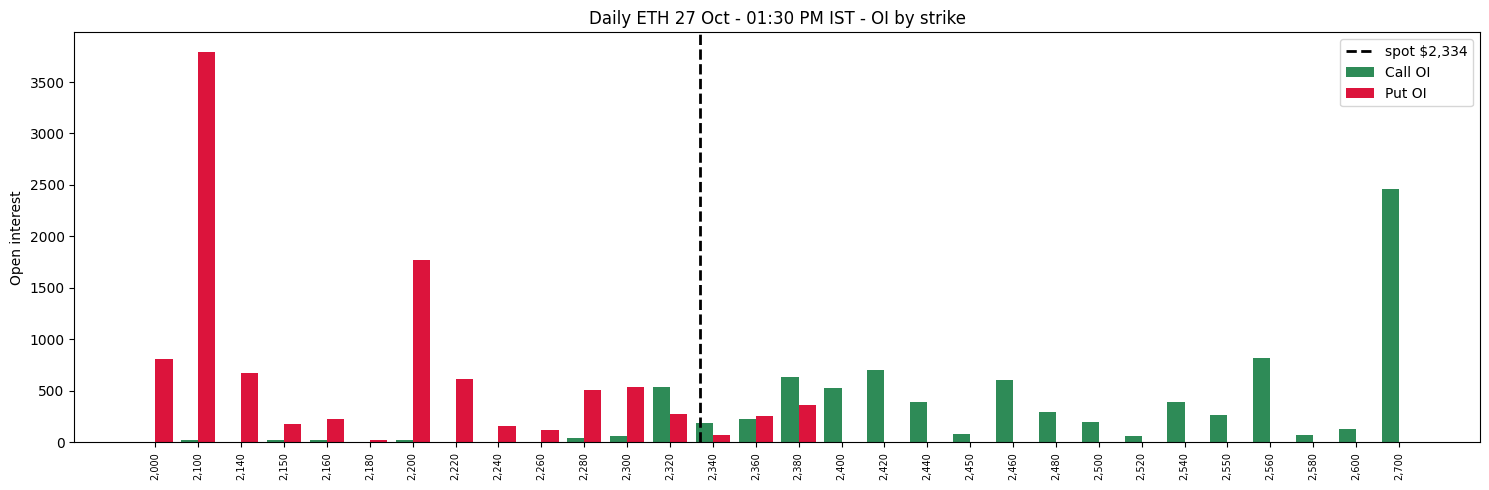

In [5]:
nearest_dt = sorted(df_daily.expiry_dt.unique())[0]
nearest = df_daily[df_daily.expiry_dt == nearest_dt]
ist_nearest = to_ist(pd.Timestamp(nearest_dt).to_pydatetime())

strikes_c = nearest[nearest.kind == 'C'].groupby('strike').oi.sum()
strikes_p = nearest[nearest.kind == 'P'].groupby('strike').oi.sum()

fig, ax = plt.subplots(figsize=(15, 5))
all_strikes = sorted(set(strikes_c.index) | set(strikes_p.index))
x = np.arange(len(all_strikes))
c_vals = [strikes_c.get(k, 0) for k in all_strikes]
p_vals = [strikes_p.get(k, 0) for k in all_strikes]

ax.bar(x - 0.2, c_vals, 0.4, label='Call OI', color='seagreen')
ax.bar(x + 0.2, p_vals, 0.4, label='Put OI',  color='crimson')
ax.axvline(np.interp(spot, all_strikes, x), color='black', lw=2, ls='--', label=f'spot ${spot:,.0f}')
ax.set_xticks(x)
ax.set_xticklabels([f'{s:,.0f}' for s in all_strikes], rotation=90, fontsize=7)
ax.set_ylabel('Open interest')
ax.set_title(f'Daily ETH {ist_nearest.strftime("%d %b - %I:%M %p IST")} - OI by strike')
ax.legend()
plt.tight_layout(); plt.show()

## 5. IV smile at daily tenor

**What this tells you:** how the market prices fear/greed at the shortest expiry. Daily IV can be **2-3x higher** than monthly IV during stress.

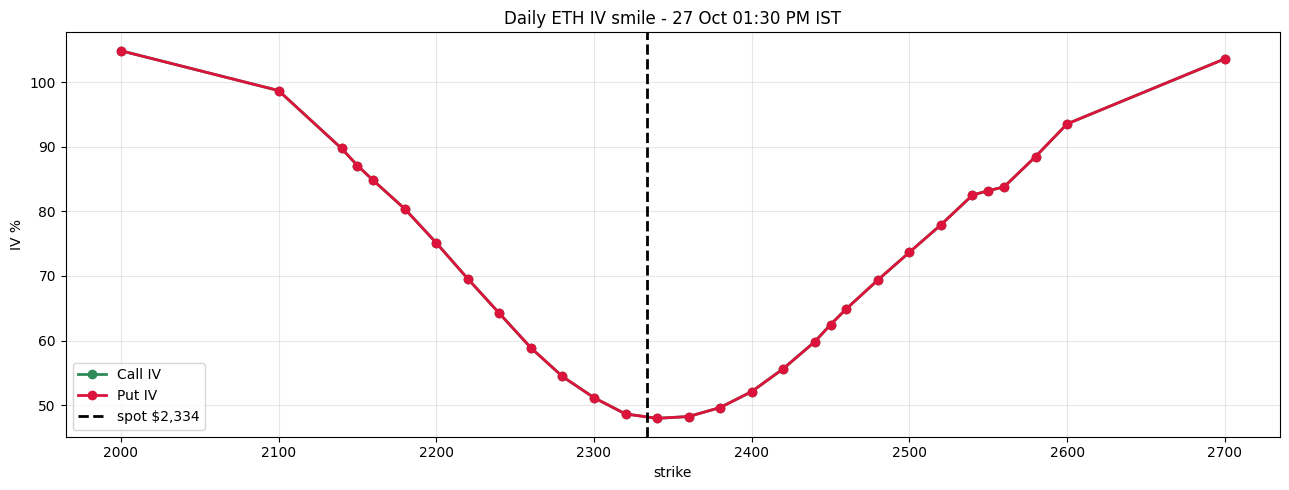


Average IV comparison:
  Daily (nearest):  72.2%
  Monthly (25-40d): 59.5%
  Ratio: 1.21x  (daily more expensive)


In [6]:
fig, ax = plt.subplots(figsize=(13, 5))

calls = nearest[(nearest.kind == 'C') & nearest.iv_dec.notna()].sort_values('strike')
puts  = nearest[(nearest.kind == 'P') & nearest.iv_dec.notna()].sort_values('strike')

if len(calls) > 0:
    ax.plot(calls.strike, calls.iv_dec * 100, 'o-', color='seagreen', label='Call IV', lw=2, ms=6)
if len(puts) > 0:
    ax.plot(puts.strike, puts.iv_dec * 100, 'o-', color='crimson', label='Put IV', lw=2, ms=6)

ax.axvline(spot, color='black', ls='--', lw=2, label=f'spot ${spot:,.0f}')
ax.set_xlabel('strike')
ax.set_ylabel('IV %')
ax.set_title(f'Daily ETH IV smile - {ist_nearest.strftime("%d %b %I:%M %p IST")}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# compare to 30-day IV
thirty_day = df_all[df_all.days.between(25, 40)]
if len(thirty_day) > 0:
    print(f'\nAverage IV comparison:')
    print(f'  Daily (nearest):  {nearest.iv_dec.mean()*100:.1f}%')
    print(f'  Monthly (25-40d): {thirty_day.iv_dec.mean()*100:.1f}%')
    ratio = nearest.iv_dec.mean() / thirty_day.iv_dec.mean()
    print(f'  Ratio: {ratio:.2f}x  ({"daily more expensive" if ratio > 1 else "daily cheaper"})')

## 6. Greeks: delta, gamma, theta

**For a daily option buyer, this is the critical section.**

- **Gamma**: highest of all tenors - explosive leverage
- **Theta**: most painful - premium bleeds every hour
- **Delta**: changes fastest - ATM options can go from 0.5 to 0.9 in hours

In [7]:
def bs_greeks(S, K, T, sigma, kind):
    if T <= 0 or sigma <= 0:
        return None
    d1 = (np.log(S/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    pdf = norm.pdf(d1)
    delta = norm.cdf(d1) if kind == 'C' else norm.cdf(d1) - 1
    gamma = pdf / (S * sigma * np.sqrt(T))
    vega  = S * pdf * np.sqrt(T) / 100
    theta = -(S * pdf * sigma) / (2 * np.sqrt(T)) / 365
    return {'delta': float(delta), 'gamma': float(gamma),
            'vega': float(vega), 'theta': float(theta)}

greeks = []
for _, r in nearest.iterrows():
    if pd.isna(r.iv_dec) or r.days <= 0:
        continue
    g = bs_greeks(spot, r.strike, r.days/365, r.iv_dec, r.kind)
    if g:
        greeks.append({**r.to_dict(), **g})

gk = pd.DataFrame(greeks)
print(f'Daily contracts with Greeks: {len(gk)}')
gk[['strike', 'kind', 'days', 'iv_dec', 'delta', 'gamma', 'vega', 'theta']].sort_values(['kind', 'strike']).head(20)

Daily contracts with Greeks: 60


,strike,kind,days,iv_dec,delta,gamma,vega,theta
40,2000.0,C,0.883913,1.0488,0.998720,0.000035,0.004848,-0.287644
32,2100.0,C,0.883913,0.9871,0.985995,0.000315,0.040999,-2.289242
14,2140.0,C,0.883913,0.8974,0.976420,0.000540,0.063906,-3.244063
30,2150.0,C,0.883913,0.8710,0.973501,0.000613,0.070475,-3.472290
12,2160.0,C,0.883913,0.8481,0.969593,0.000706,0.079021,-3.790961
46,2180.0,C,0.883913,0.8040,0.959290,0.000947,0.100391,-4.565747
11,2200.0,C,0.883913,0.7513,0.946849,0.001255,0.124345,-5.284495
43,2220.0,C,0.883913,0.6957,0.930153,0.001678,0.153943,-6.058169
44,2240.0,C,0.883913,0.6422,0.905482,0.002283,0.193385,-7.025131
17,2260.0,C,0.883913,0.5888,0.869287,0.003140,0.243872,-8.122508


## 7. Gamma and Theta visualization

**What this tells you:** daily options have **extreme gamma but brutal theta**. The chart shows where gamma peaks and where theta hurts most.

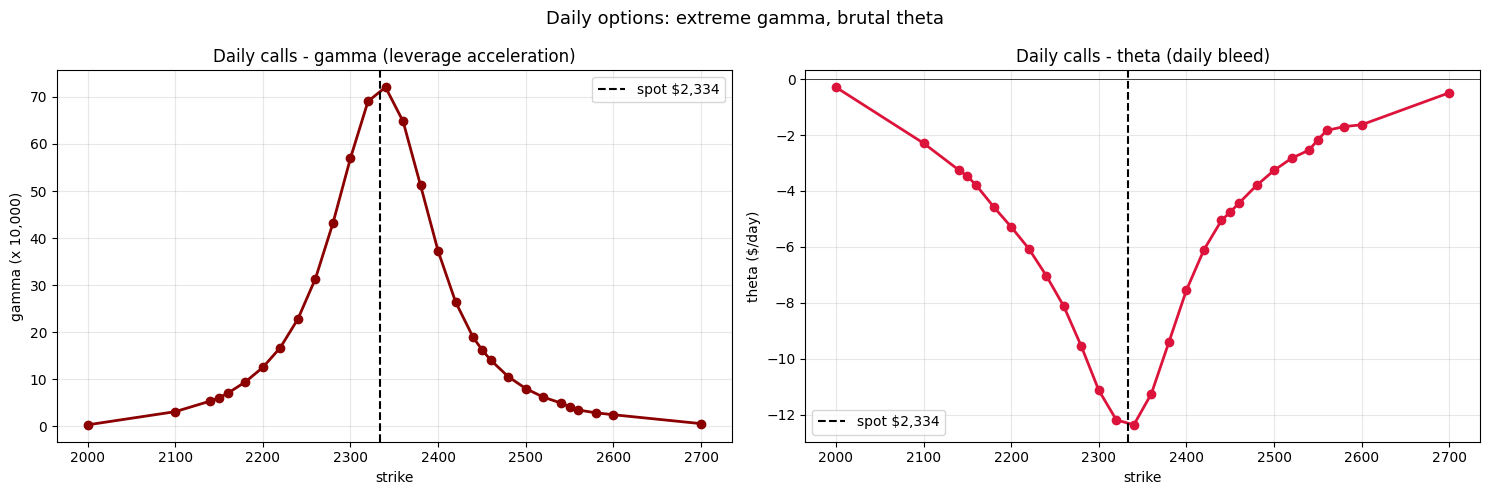

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

calls = gk[gk.kind == 'C'].sort_values('strike')
if len(calls) > 0:
    axes[0].plot(calls.strike, calls.gamma * 10000, 'o-', color='darkred', lw=2, ms=6)
    axes[0].axvline(spot, color='black', ls='--', lw=1.5, label=f'spot ${spot:,.0f}')
    axes[0].set_xlabel('strike'); axes[0].set_ylabel('gamma (x 10,000)')
    axes[0].set_title('Daily calls - gamma (leverage acceleration)')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(calls.strike, calls.theta, 'o-', color='crimson', lw=2, ms=6)
    axes[1].axvline(spot, color='black', ls='--', lw=1.5, label=f'spot ${spot:,.0f}')
    axes[1].axhline(0, color='black', lw=0.5)
    axes[1].set_xlabel('strike'); axes[1].set_ylabel('theta ($/day)')
    axes[1].set_title('Daily calls - theta (daily bleed)')
    axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle('Daily options: extreme gamma, brutal theta', fontsize=13)
plt.tight_layout(); plt.show()

## 8. Theta burn per hour

**For a daily option, theta is hourly, not daily.**

The last 6 hours before expiry can destroy 30-50% of premium if the option is ATM and spot hasn't moved.

### 8.1 Time decay curve

**What this tells you:** how much premium an ATM option loses as the day progresses toward 1:30 PM IST expiry.

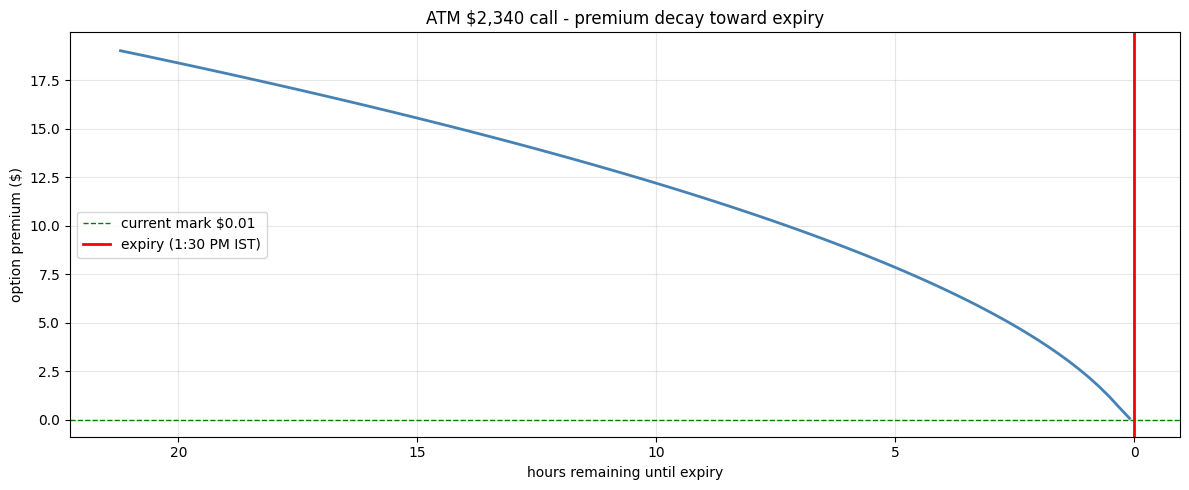

ATM $2,340 call analysis:
  Current mark    : $0.01
  Hours to expiry : 21.2
  Theta/day       : $12.37
  Theta/hour      : $0.52


In [9]:
if len(calls) > 0:
    atm_call = calls.iloc[(calls.strike - spot).abs().argsort()[:1]].iloc[0]
    K = atm_call.strike
    sigma = atm_call.iv_dec
    hours_left = atm_call.days * 24

    hours_range = np.linspace(hours_left, 0.1, 100)
    prices = []
    for h in hours_range:
        T = h / (24 * 365)
        if T <= 0: break
        d1 = (np.log(spot/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        price = spot * norm.cdf(d1) - K * norm.cdf(d2)
        prices.append(price)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(hours_range[:len(prices)], prices, lw=2, color='steelblue')
    ax.axhline(atm_call.mark, color='green', ls='--', lw=1, label=f'current mark ${atm_call.mark:.2f}')
    ax.axvline(0, color='red', lw=2, label='expiry (1:30 PM IST)')
    ax.set_xlabel('hours remaining until expiry')
    ax.set_ylabel('option premium ($)')
    ax.set_title(f'ATM ${K:,.0f} call - premium decay toward expiry')
    ax.invert_xaxis()
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    print(f'ATM ${K:,.0f} call analysis:')
    print(f'  Current mark    : ${atm_call.mark:.2f}')
    print(f'  Hours to expiry : {hours_left:.1f}')
    print(f'  Theta/day       : ${abs(atm_call.theta):.2f}')
    print(f'  Theta/hour      : ${abs(atm_call.theta)/24:.2f}')

## 9. Strike-by-strike breakeven

**What this tells you:** for each call and put, what price does ETH need to reach **by 1:30 PM IST** for the option to be profitable at expiry?

In [10]:
print('=' * 72)
print('DAILY BREAKEVEN AT EXPIRY (1:30 PM IST)')
print('=' * 72)
print()

for kind_label, kind_code in [('CALLS', 'C'), ('PUTS', 'P')]:
    s = gk[(gk.kind == kind_code) & gk.mark.notna()].copy()
    s = s[(s.strike > spot * 0.95) & (s.strike < spot * 1.05)].sort_values('strike')
    if len(s) == 0: continue

    print(f'--- {kind_label} near the money ---')
    for _, r in s.iterrows():
        if kind_code == 'C':
            breakeven = r.strike + r.mark
        else:
            breakeven = r.strike - r.mark
        move_needed = (breakeven - spot) / spot * 100
        print(f'  ${r.strike:,.0f} {kind_code}  mark=${r.mark:.2f}  '
              f'breakeven=${breakeven:,.0f}  move needed: {move_needed:+.2f}%')
    print()

DAILY BREAKEVEN AT EXPIRY (1:30 PM IST)

--- CALLS near the money ---
  $2,220 C  mark=$0.05  breakeven=$2,220  move needed: -4.87%
  $2,240 C  mark=$0.04  breakeven=$2,240  move needed: -4.02%
  $2,260 C  mark=$0.03  breakeven=$2,260  move needed: -3.16%
  $2,280 C  mark=$0.02  breakeven=$2,280  move needed: -2.30%
  $2,300 C  mark=$0.02  breakeven=$2,300  move needed: -1.45%
  $2,320 C  mark=$0.01  breakeven=$2,320  move needed: -0.59%
  $2,340 C  mark=$0.01  breakeven=$2,340  move needed: +0.27%
  $2,360 C  mark=$0.00  breakeven=$2,360  move needed: +1.12%
  $2,380 C  mark=$0.00  breakeven=$2,380  move needed: +1.98%
  $2,400 C  mark=$0.00  breakeven=$2,400  move needed: +2.84%
  $2,420 C  mark=$0.00  breakeven=$2,420  move needed: +3.69%
  $2,440 C  mark=$0.00  breakeven=$2,440  move needed: +4.55%
  $2,450 C  mark=$0.00  breakeven=$2,450  move needed: +4.98%

--- PUTS near the money ---
  $2,220 P  mark=$0.00  breakeven=$2,220  move needed: -4.87%
  $2,240 P  mark=$0.00  breakeven

## 10. Liquidity check

**The critical filter:** can you actually get in and out? Daily options are usually thin - wide spreads eat your profit.

In [11]:
nearest_liquid = nearest[(nearest.bid > 0) & (nearest.ask > 0)].copy()
nearest_liquid['spread_%'] = nearest_liquid.spread_pct * 100

print('=' * 72)
print('LIQUIDITY BY STRIKE (nearest expiry)')
print('=' * 72)

liquid_near = nearest_liquid[(nearest_liquid.strike > spot * 0.95) & 
                              (nearest_liquid.strike < spot * 1.05)].sort_values('strike')

print(f"{'Strike':<10} {'Kind':<5} {'Bid':<10} {'Ask':<10} {'Spread%':<10} {'OI':<10} {'Volume':<10}")
print('-' * 70)
for _, r in liquid_near.iterrows():
    print(f"${r.strike:,.0f}   {r.kind:<5} ${r.bid:<9.2f} ${r.ask:<9.2f} "
          f"{r['spread_%']:<10.1f} {r.oi:<10.0f} {r.volume:<10.0f}")

LIQUIDITY BY STRIKE (nearest expiry)
Strike     Kind  Bid        Ask        Spread%    OI         Volume    
----------------------------------------------------------------------
$2,220   P     $0.00      $0.00      15.4       615        279       
$2,220   C     $0.05      $0.05      6.3        0          0         
$2,240   C     $0.04      $0.04      7.7        0          0         
$2,240   P     $0.00      $0.00      11.8       162        176       
$2,260   C     $0.03      $0.03      9.7        0          0         
$2,260   P     $0.00      $0.00      8.7        118        95        
$2,280   P     $0.00      $0.00      9.0        511        521       
$2,280   C     $0.02      $0.03      10.5       45         1         
$2,300   P     $0.00      $0.01      11.5       533        504       
$2,300   C     $0.02      $0.02      11.8       57         74        
$2,320   P     $0.01      $0.01      6.5        272        237       
$2,320   C     $0.01      $0.01      9.1        53

## 11. Best daily contract for a buyer

**The buyer's scoring:**

- Delta 0.30-0.50 (real leverage)
- Gamma/theta ratio (efficiency)
- Tight spread (can actually trade)
- Reasonable OI (can exit)

In [12]:
near_atm = nearest_liquid[(nearest_liquid.strike > spot * 0.93) &
                          (nearest_liquid.strike < spot * 1.07) &
                          (nearest_liquid.oi > 10)].copy()

if len(near_atm) > 0:
    # merge greeks
    near_atm = near_atm.merge(gk[['strike', 'kind', 'delta', 'gamma', 'vega', 'theta']],
                               on=['strike', 'kind'], how='left')
    near_atm = near_atm[near_atm.delta.notna()]

    # scoring
    near_atm['delta_fit'] = 1 - abs(near_atm.delta.abs() - 0.40) / 0.40
    near_atm['gt_ratio'] = near_atm.gamma / (near_atm.theta.abs() + 1e-9)
    near_atm['gt_norm'] = (near_atm.gt_ratio - near_atm.gt_ratio.min()) / (near_atm.gt_ratio.max() - near_atm.gt_ratio.min() + 1e-9)
    near_atm['spread_score'] = 1 - near_atm['spread_%'] / 100

    near_atm['buyer_score'] = (
        0.40 * near_atm.delta_fit
        + 0.35 * near_atm.gt_norm
        + 0.25 * near_atm.spread_score
    )

    best = near_atm.nlargest(5, 'buyer_score')

    print('=' * 72)
    print('TOP 5 DAILY CONTRACTS FOR BUYERS')
    print('=' * 72)
    print()
    for _, r in best.iterrows():
        print(f"${r.strike:,.0f} {r.kind}  {r.days:.2f}d  score={r.buyer_score:.3f}")
        print(f"  mark=${r.mark:.2f}  spread={r['spread_%']:.1f}%  OI={r.oi:.0f}")
        print(f"  delta={r.delta:.3f}  gamma={r.gamma*10000:.2f}x10k  theta=${r.theta:.2f}/day")
        print()
else:
    print('No liquid daily contracts near the money')

TOP 5 DAILY CONTRACTS FOR BUYERS

$2,320 P  0.88d  score=0.967
  mark=$0.01  spread=6.5%  OI=272
  delta=-0.398  gamma=69.06x10k  theta=$-12.19/day

$2,360 C  0.88d  score=0.905
  mark=$0.00  spread=4.9%  OI=222
  delta=0.323  gamma=64.81x10k  theta=$-11.25/day

$2,340 C  0.88d  score=0.905
  mark=$0.01  spread=14.3%  OI=190
  delta=0.460  gamma=72.06x10k  theta=$-12.37/day

$2,340 P  0.88d  score=0.839
  mark=$0.01  spread=8.3%  OI=68
  delta=-0.540  gamma=72.06x10k  theta=$-12.37/day

$2,300 P  0.88d  score=0.782
  mark=$0.01  spread=11.5%  OI=533
  delta=-0.277  gamma=57.00x10k  theta=$-11.13/day



## 12. The daily option buyer's reality check

**The honest questions before buying a daily option:**

1. **How much premium will I lose by tomorrow 1:30 PM IST?**
2. **What price does ETH need to reach to break even?**
3. **Is the spread going to eat most of my edge?**
4. **Do I have a real catalyst in the next 24 hours?**

In [13]:
print('=' * 72)
print('DAILY OPTION BUYER - REALITY CHECK')
print('=' * 72)
print()

if len(gk) > 0:
    atm = gk.iloc[(gk.strike - spot).abs().argsort()[:1]].iloc[0]
    print(f'ATM ${atm.strike:,.0f} {atm.kind} option:')
    print(f'  Current mark       : ${atm.mark:.2f}')
    print(f'  Time to expiry     : {atm.days*24:.1f} hours (expires 1:30 PM IST)')
    print(f'  Theta per hour     : ${abs(atm.theta)/24:.3f}')
    print(f'  Premium lost by expiry (no move): -${atm.mark:.2f} (-100%)')
    print()
    print(f'  To break even:')
    if atm.kind == 'C':
        be = atm.strike + atm.mark
        move = (be - spot) / spot * 100
    else:
        be = atm.strike - atm.mark
        move = (be - spot) / spot * 100
    print(f'    ETH must move to ${be:,.2f} ({move:+.2f}%)')
    print(f'    before 1:30 PM IST tomorrow')
    print()
    print('-' * 72)
    print('THE HONEST TRUTH ABOUT DAILY OPTIONS:')
    print('-' * 72)
    print()
    print('  - You need a 1-2% move in your direction')
    print('    within 24 hours JUST to break even')
    print()
    print('  - Theta bleeds your premium every hour')
    print('    even if price does nothing')
    print()
    print('  - Spreads on daily options are usually 5-15%')
    print('    meaning you start down 2-7% on entry')
    print()
    print('  - For a profitable trade, ETH needs a 2-3% move')
    print('    in under 24 hours in your exact direction')
    print()
    print('  - WRONG for most buyers, RIGHT for traders with')
    print('    a strong catalyst view (news, FOMC, etc.)')
    print()
    print('  RULE: only buy daily options when you have a REAL')
    print('  reason to believe a 2-3% move is coming TODAY.')

DAILY OPTION BUYER - REALITY CHECK

ATM $2,340 P option:
  Current mark       : $0.01
  Time to expiry     : 21.2 hours (expires 1:30 PM IST)
  Theta per hour     : $0.515
  Premium lost by expiry (no move): -$0.01 (-100%)

  To break even:
    ETH must move to $2,339.99 (+0.27%)
    before 1:30 PM IST tomorrow

------------------------------------------------------------------------
THE HONEST TRUTH ABOUT DAILY OPTIONS:
------------------------------------------------------------------------

  - You need a 1-2% move in your direction
    within 24 hours JUST to break even

  - Theta bleeds your premium every hour
    even if price does nothing

  - Spreads on daily options are usually 5-15%
    meaning you start down 2-7% on entry

  - For a profitable trade, ETH needs a 2-3% move
    in under 24 hours in your exact direction

  - WRONG for most buyers, RIGHT for traders with
    a strong catalyst view (news, FOMC, etc.)

  RULE: only buy daily options when you have a REAL
  reason t

## 13. Summary

The complete picture of the daily option opportunity.

In [14]:
print('=' * 72)
print('ETH DAILY OPTIONS - SUMMARY')
print('=' * 72)
print()
print(f'  Spot                 : ${spot:,.2f}')
print(f'  Daily expiries found : {len(daily_expiries)}')
print(f'  Total daily contracts: {len(df_daily)}')
print(f'  Total daily OI       : {df_daily.oi.sum():,.0f}')
print(f'  Total daily volume   : {df_daily.volume.sum():,.0f}')
print()
print('Expiry schedule (IST):')
for _, e in daily_expiries.iterrows():
    ist = to_ist(e['expiry_dt'].to_pydatetime())
    print(f"  {ist.strftime('%A %d %B - %I:%M %p IST')}  ({e['days']:.1f}d)")
print()
print('=' * 72)
print('BOTTOM LINE')
print('=' * 72)
print()
print('  Daily options settle at 1:30 PM IST every day.')
print()
print('  They are:')
print('  - The cheapest premium on the chain')
print('  - The highest gamma (max leverage)')
print('  - The worst theta (100% loss if no move)')
print('  - The thinnest liquidity')
print()
print('  Only trade them when:')
print('  1. You expect a 2-3% move TODAY')
print('  2. You have a real catalyst (news, events)')
print('  3. The spread is under 10%')
print('  4. The OI is above 100 (can exit)')
print()
print('  Otherwise, buy 2-4 week options instead: ')
print('  - Less theta burn')
print('  - Better liquidity')
print('  - Time for your thesis to play out')
print()
print('=' * 72)

ETH DAILY OPTIONS - SUMMARY

  Spot                 : $2,333.77
  Daily expiries found : 3
  Total daily contracts: 170
  Total daily OI       : 33,840
  Total daily volume   : 24,855

Expiry schedule (IST):
  Tuesday 27 October - 01:30 PM IST  (0.9d)
  Wednesday 28 October - 01:30 PM IST  (1.9d)
  Thursday 29 October - 01:30 PM IST  (2.9d)

BOTTOM LINE

  Daily options settle at 1:30 PM IST every day.

  They are:
  - The cheapest premium on the chain
  - The highest gamma (max leverage)
  - The worst theta (100% loss if no move)
  - The thinnest liquidity

  Only trade them when:
  1. You expect a 2-3% move TODAY
  2. You have a real catalyst (news, events)
  3. The spread is under 10%
  4. The OI is above 100 (can exit)

  Otherwise, buy 2-4 week options instead: 
  - Less theta burn
  - Better liquidity
  - Time for your thesis to play out



## Notes

**Daily option characteristics:**

| Metric | Daily | 30-day |
|---|---|---|
| Theta per day | 10-50% of premium | 1-3% of premium |
| Gamma | Highest | Moderate |
| Vega | Very low | Moderate |
| Liquidity | Thin | Deep |
| Spread | 5-15% | 1-5% |

**IST timing:**
- Every day at **1:30 PM IST** = settlement
- Daily options are listed the day before
- Last 4 hours (9:30 AM - 1:30 PM IST) = highest gamma, fastest decay

**Data notes:**
- Live from Deribit, no storage
- Expiries shown in IST throughout
- All Greeks computed with Black-Scholes